# What my Liked Songs say about my taste

Three questions, using `liked_songs_clean.csv` (built in `build_dataset.ipynb`):

1. **How has my taste changed over time?**
2. **Do my songs fall into natural "taste groups"?** (clustering on how songs sound)
3. **Can a song's sound and basic facts predict whether it's popular?**

Charts are saved to `figures/` so the README can use them.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, silhouette_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Chart colors: a colorblind-checked categorical palette, used in this fixed order
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
OTHER_GRAY = "#c3c2b7"
TEXT, TEXT_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": TEXT_2, "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "text.color": TEXT, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold",
    "legend.frameon": False, "font.size": 10, "figure.dpi": 110,
})
FIG = Path("figures")
FIG.mkdir(exist_ok=True)

df = pd.read_csv("liked_songs_clean.csv")
# 2015 has only 12 songs (I started liking songs late that year), so it's grouped with 2016
df["year"] = df["liked_year"].clip(lower=2016)
YEAR_LABELS = {2026: "2026*"}
year_label = lambda y: YEAR_LABELS.get(y, str(y))
print(f"{len(df)} songs, {df['energy'].notna().sum()} with audio features")

4811 songs, 3407 with audio features


## 1. How my taste changed over time

\* 2026 only runs through October 13, so its counts are partial (shares and medians are still comparable). The 2016 bar also includes the 12 songs I liked in late 2015.

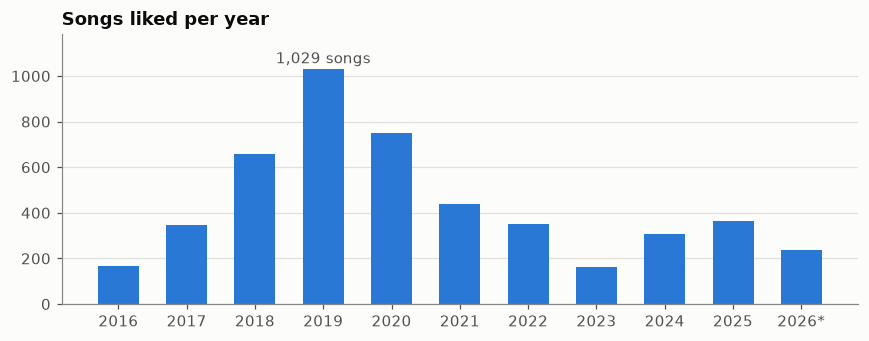

In [2]:
per_year = df["year"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(per_year.index, per_year.values, width=0.6, color=COLORS[0])
ax.set_xticks(per_year.index, [year_label(y) for y in per_year.index])
ax.grid(axis="x", visible=False)
peak = per_year.idxmax()
ax.annotate(f"{per_year[peak]:,} songs", (peak, per_year[peak]), xytext=(0, 4),
            textcoords="offset points", ha="center", color=TEXT_2)
ax.set_ylim(0, per_year.max() * 1.15)
ax.set_title("Songs liked per year")
fig.tight_layout()
fig.savefig(FIG / "songs_per_year.png")
plt.show()

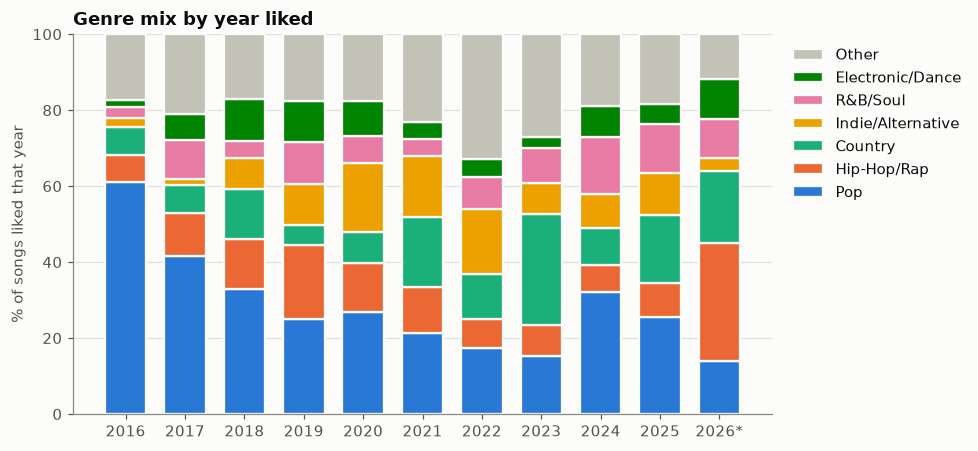

main_genre  Pop  Hip-Hop/Rap  Country  Indie/Alternative  R&B/Soul  Electronic/Dance  Other
year                                                                                       
2016         61            7        7                  2         3                 2     17
2017         41           12        7                  2        10                 7     21
2018         33           13       13                  8         5                11     17
2019         25           20        5                 11        11                11     18
2020         27           13        8                 18         7                 9     18
2021         21           12       18                 16         4                 5     23
2022         17            8       12                 17         8                 5     33
2023         15            8       29                  8         9                 3     27
2024         32            7       10                  9        15              

In [3]:
# Genre mix per year: the 6 biggest genres overall, everything else grouped as "Other"
top_genres = df.loc[df["main_genre"] != "Unknown", "main_genre"].value_counts().head(6).index.tolist()
genre = df["main_genre"].where(df["main_genre"].isin(top_genres), "Other")
mix = pd.crosstab(df["year"], genre, normalize="index")[top_genres + ["Other"]] * 100

fig, ax = plt.subplots(figsize=(9, 4.2))
bottom = np.zeros(len(mix))
for i, g in enumerate(mix.columns):
    color = OTHER_GRAY if g == "Other" else COLORS[i]
    ax.bar(mix.index, mix[g], bottom=bottom, width=0.7, color=color, label=g, edgecolor=SURFACE, linewidth=1.5)
    bottom += mix[g].values
ax.set_xticks(mix.index, [year_label(y) for y in mix.index])
ax.set_ylabel("% of songs liked that year")
ax.set_ylim(0, 100)
ax.grid(axis="x", visible=False)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", reverse=True)
ax.set_title("Genre mix by year liked")
fig.tight_layout()
fig.savefig(FIG / "genre_mix_by_year.png")
plt.show()

print(mix.round(0).astype(int).rename(index=year_label).to_string())

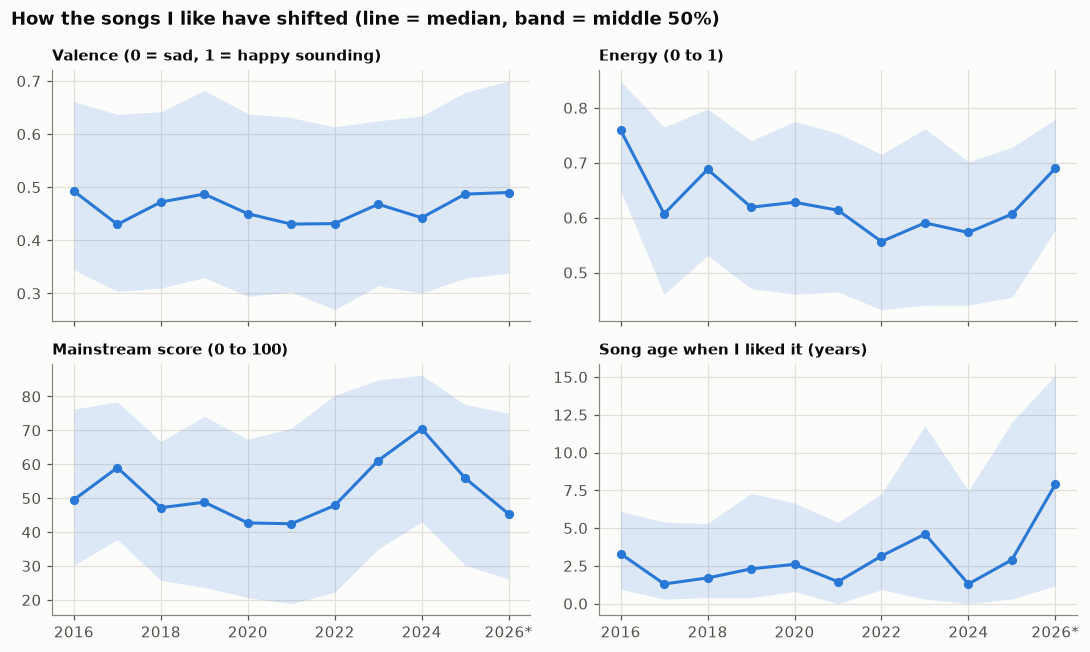

       songs  valence  energy  acousticness  mainstream  song_age  pct_explicit  pct_binge
year                                                                                      
2016     167     0.49    0.76          0.06       49.55      3.30          5.99       7.78
2017     347     0.43    0.61          0.13       59.00      1.30         12.39      18.44
2018     659     0.47    0.69          0.13       47.20      1.70         18.82      34.29
2019    1029     0.49    0.62          0.18       48.80      2.30         27.41      47.13
2020     751     0.45    0.63          0.19       42.70      2.60         21.97      34.49
2021     438     0.43    0.61          0.19       42.45      1.45         18.95      24.43
2022     350     0.43    0.56          0.29       47.85      3.15         19.14      30.29
2023     163     0.47    0.59          0.20       61.10      4.60         25.15       5.52
2024     306     0.44    0.57          0.32       70.45      1.30         28.76      15.03

In [4]:
# Yearly medians for four "what kind of song" measures. Each gets its own panel (and its own scale).
TRENDS = {
    "valence": "Valence (0 = sad, 1 = happy sounding)",
    "energy": "Energy (0 to 1)",
    "mainstream_score": "Mainstream score (0 to 100)",
    "song_age_when_liked": "Song age when I liked it (years)",
}
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, (col, title) in zip(axes.flat, TRENDS.items()):
    g = df.groupby("year")[col]
    ax.fill_between(g.median().index, g.quantile(.25), g.quantile(.75), color=COLORS[0], alpha=.15, linewidth=0)
    ax.plot(g.median().index, g.median(), color=COLORS[0], linewidth=2, marker="o", markersize=5)
    ax.set_title(title, fontsize=10)
    ax.set_xticks(per_year.index[::2], [year_label(y) for y in per_year.index[::2]])
fig.suptitle("How the songs I like have shifted (line = median, band = middle 50%)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "trends_by_year.png")
plt.show()

yearly = df.groupby("year").agg(
    songs=("track", "size"),
    valence=("valence", "median"),
    energy=("energy", "median"),
    acousticness=("acousticness", "median"),
    mainstream=("mainstream_score", "median"),
    song_age=("song_age_when_liked", "median"),
    pct_explicit=("explicit", "mean"),
    pct_binge=("binge_day", "mean"),
).rename(index=year_label)
yearly[["pct_explicit", "pct_binge"]] *= 100
print(yearly.round(2).to_string())

## 2. Taste groups (clustering)

K-means groups songs that sound alike, using only the audio features (about 70% of my songs have them). Popularity and genre are left out on purpose, so I can check afterwards whether the sound-based groups line up with genres.

Features are standardized first (so tempo, measured in the 100s, doesn't outweigh 0-to-1 features). To pick the number of groups I look at two things for 2 to 8 groups:
- **Inertia**: how tight the groups are (always drops as groups are added, look for where it levels off).
- **Silhouette**: how well separated the groups are (higher is better; under ~0.2 means the groups overlap a lot).

In [5]:
AUDIO = ["danceability", "energy", "valence", "acousticness", "speechiness",
         "instrumentalness", "liveness", "tempo", "loudness"]
songs_audio = df.dropna(subset=AUDIO).copy()
X = StandardScaler().fit_transform(songs_audio[AUDIO])

for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    sil = silhouette_score(X, km.labels_, sample_size=2000, random_state=42)
    print(f"k={k}: inertia {km.inertia_:8.0f}   silhouette {sil:.3f}")

k=2: inertia    24326   silhouette 0.242


k=3: inertia    21644   silhouette 0.237


k=4: inertia    19419   silhouette 0.239


k=5: inertia    17639   silhouette 0.177


k=6: inertia    16184   silhouette 0.179
k=7: inertia    14949   silhouette 0.162


k=8: inertia    14204   silhouette 0.155


In [6]:
# k=4: nearly the best silhouette (k=2 and k=3 are similar but too broad to be useful), and k=5+ scores clearly worse.
# All scores are low (about 0.24), meaning the groups overlap. Music blends together, so these are
# "regions" of my taste rather than sharply separate types.
K = 4
km = KMeans(n_clusters=K, n_init=20, random_state=42).fit(X)
songs_audio["cluster"] = km.labels_

# Average of each feature per group, in standard deviations from my overall average
profile = pd.DataFrame(km.cluster_centers_, columns=AUDIO)

# Name each group from its standout feature (so names don't depend on K-means' arbitrary numbering)
names = {}
names[profile["instrumentalness"].idxmax()] = "Instrumental & atmospheric"
names[profile["speechiness"].drop(list(names)).idxmax()] = "Rap & vocal-heavy"
names[profile["acousticness"].drop(list(names)).idxmax()] = "Soft & acoustic"
names[profile.index.difference(list(names))[0]] = "Upbeat & loud"
songs_audio["taste_group"] = songs_audio["cluster"].map(names)

profile.index = profile.index.map(names)
profile.insert(0, "songs", songs_audio["taste_group"].value_counts())
print(profile.sort_values("songs", ascending=False).round(2).to_string())

                            songs  danceability  energy  valence  acousticness  speechiness  instrumentalness  liveness  tempo  loudness
Upbeat & loud                1983          0.15    0.56     0.33         -0.53        -0.24             -0.15      0.04   0.06      0.49
Soft & acoustic              1010         -0.46   -1.08    -0.62          1.05        -0.33             -0.11     -0.10  -0.13     -0.86
Rap & vocal-heavy             335          0.63    0.08     0.02         -0.25         2.49             -0.18      0.08   0.07      0.08
Instrumental & atmospheric     78         -0.61   -0.73    -0.47          0.83        -0.26              5.95     -0.12  -0.17     -1.56


In [7]:
# What's in each group: genre, popularity, and the 4 songs closest to the group's center
dist = km.transform(X)
songs_audio["dist"] = dist[np.arange(len(X)), songs_audio["cluster"]]
GROUP_ORDER = ["Upbeat & loud", "Soft & acoustic", "Rap & vocal-heavy", "Instrumental & atmospheric"]
for name in GROUP_ORDER:
    g = songs_audio[songs_audio["taste_group"] == name]
    genres = g["main_genre"].value_counts(normalize=True).head(3)
    print(f"--- {name}: {len(g)} songs ---")
    print("  Top genres: " + ", ".join(f"{k} {v:.0%}" for k, v in genres.items()))
    print(f"  Median mainstream score {g['mainstream_score'].median():.0f}, "
          f"median release year {g['release_year'].median():.0f}, explicit {g['explicit'].mean():.0%}")
    for _, s in g.nsmallest(4, "dist").iterrows():
        print(f"    {s['track']} - {s['artist']}")

--- Upbeat & loud: 1983 songs ---
  Top genres: Pop 33%, Country 13%, Hip-Hop/Rap 11%
  Median mainstream score 52, median release year 2017, explicit 20%
    Starlight (Taylor's Version) - Taylor Swift
    Am I Okay? - Megan Moroney
    Defenceless - Louis Tomlinson
    OK - Robin Schulz
--- Soft & acoustic: 1010 songs ---
  Top genres: Pop 28%, Folk/Acoustic 15%, Country 13%
  Median mainstream score 54, median release year 2018, explicit 16%


    Sober - Bazzi
    Moral of the Story - Ashe
    Tenerife Sea - Ed Sheeran
    I Love You, I'm Sorry - Gracie Abrams
--- Rap & vocal-heavy: 335 songs ---
  Top genres: Hip-Hop/Rap 55%, Pop 17%, R&B/Soul 12%
  Median mainstream score 56, median release year 2017, explicit 67%
    Sad Tonight - Chelsea Cutler
    Telephone Calls (feat. A$AP Rocky, Tyler, The Creator, Playboi Carti & Yung Gleesh) - A$AP Mob
    Superhero (Heroes & Villains) [with Future & Chris Brown] - Metro Boomin
    Garden (Say It Like Dat) - SZA
--- Instrumental & atmospheric: 78 songs ---
  Top genres: Electronic/Dance 17%, R&B/Soul 15%, Indie/Alternative 14%
  Median mainstream score 40, median release year 2017, explicit 8%
    Carolina - Young Mister
    Ribs - Lorde
    My Bad - Khalid
    Heaven - Khalid


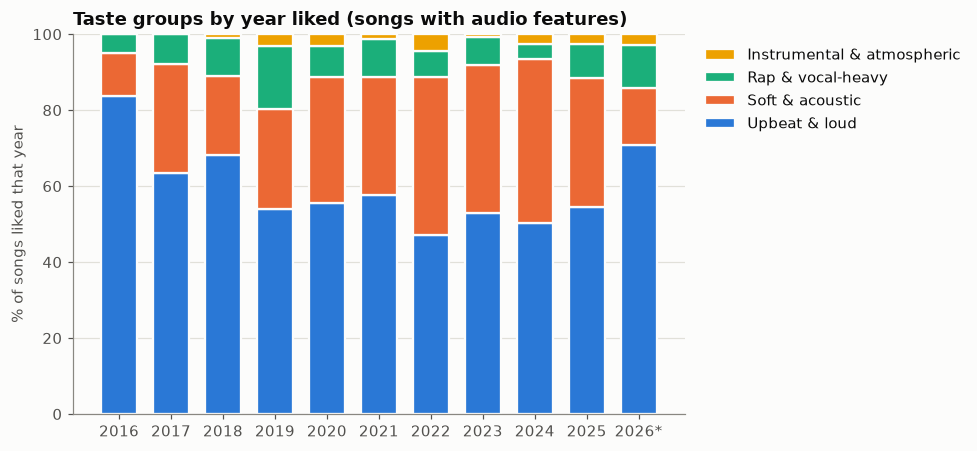

taste_group  Upbeat & loud  Soft & acoustic  Rap & vocal-heavy  Instrumental & atmospheric
year                                                                                      
2016                    84               11                  5                           0
2017                    63               29                  8                           0
2018                    68               21                 10                           1
2019                    54               26                 16                           3
2020                    56               33                  8                           3
2021                    58               31                 10                           1
2022                    47               42                  7                           4
2023                    53               39                  7                           1
2024                    50               43                  4                           2

In [8]:
# How the groups' share of my likes changed over time
share = pd.crosstab(songs_audio["year"], songs_audio["taste_group"], normalize="index")[GROUP_ORDER] * 100

fig, ax = plt.subplots(figsize=(9, 4.2))
bottom = np.zeros(len(share))
for i, g in enumerate(GROUP_ORDER):
    ax.bar(share.index, share[g], bottom=bottom, width=0.7, color=COLORS[i], label=g, edgecolor=SURFACE, linewidth=1.5)
    bottom += share[g].values
ax.set_xticks(share.index, [year_label(y) for y in share.index])
ax.set_ylabel("% of songs liked that year")
ax.set_ylim(0, 100)
ax.grid(axis="x", visible=False)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", reverse=True)
ax.set_title("Taste groups by year liked (songs with audio features)")
fig.tight_layout()
fig.savefig(FIG / "taste_groups_by_year.png")
plt.show()

print(share.round(0).astype(int).rename(index=year_label).to_string())

## 3. Can sound and basic facts predict popularity?

**Target:** is the song in the top third of my songs by Last.fm listeners (`popularity_tier == "high"`)?

**Model A** uses only things about the song itself: audio features, genre, release year, length, explicit, collab, single, and title features.
**Model B** adds one thing: how many Last.fm listeners the *artist* has. This shows how much of a song's popularity is really the artist's fame.

Each model is scored with 5-fold cross-validation using **ROC AUC**: 0.5 is a coin flip, 1.0 is perfect. Two model types are compared: logistic regression (simple, linear) and a random forest (can pick up non-linear patterns).

In [9]:
model_df = songs_audio.dropna(subset=["popularity_tier", "lfm_artist_listeners"]).copy()
y = (model_df["popularity_tier"] == "high").astype(int)

BASIC = AUDIO + ["release_year", "duration_ms", "n_artists", "title_words"]
FLAGS = ["explicit", "is_collab", "is_single", "has_feat", "is_remix"]
X_a = pd.concat([model_df[BASIC], model_df[FLAGS].astype(int),
                 pd.get_dummies(model_df["main_genre"], prefix="genre", dtype=int)], axis=1)
X_b = X_a.assign(log_artist_listeners=np.log10(model_df["lfm_artist_listeners"] + 1))
print(f"{len(model_df)} songs, {y.mean():.0%} in the 'high' group, {X_a.shape[1]} features in model A")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5, random_state=42, n_jobs=-1),
}
results = {}
for name, model in models.items():
    for label, X_ in [("A: song only", X_a), ("B: + artist fame", X_b)]:
        auc = cross_val_score(model, X_, y, cv=cv, scoring="roc_auc")
        results[(name, label)] = auc
        print(f"{name:20} {label:18} AUC {auc.mean():.3f} (+/- {auc.std():.3f})")

3405 songs, 35% in the 'high' group, 30 features in model A
Logistic regression  A: song only       AUC 0.726 (+/- 0.016)


Logistic regression  B: + artist fame   AUC 0.852 (+/- 0.017)


Random forest        A: song only       AUC 0.751 (+/- 0.014)


Random forest        B: + artist fame   AUC 0.871 (+/- 0.015)


Held-out AUC: 0.741


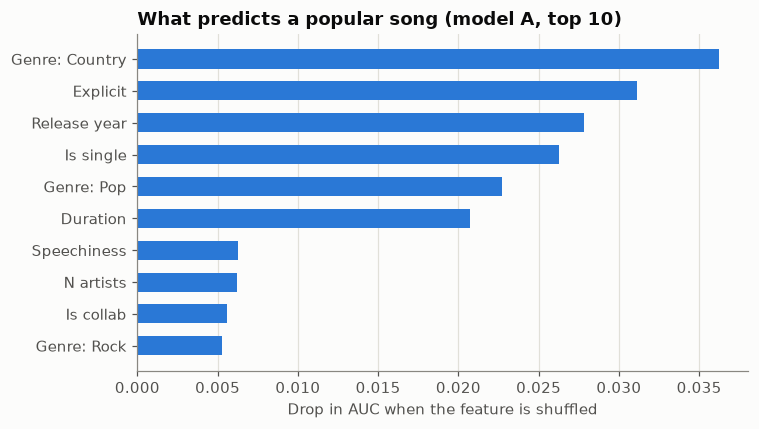

In [10]:
# Which features matter most in model A? Permutation importance: shuffle one feature
# on held-out songs and measure how much the AUC drops.
X_tr, X_te, y_tr, y_te = train_test_split(X_a, y, test_size=0.25, stratify=y, random_state=42)
rf = RandomForestClassifier(n_estimators=400, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
print(f"Held-out AUC: {roc_auc_score(y_te, rf.predict_proba(X_te)[:, 1]):.3f}")
imp = permutation_importance(rf, X_te, y_te, scoring="roc_auc", n_repeats=10, random_state=42)
imp = pd.Series(imp.importances_mean, index=X_a.columns).sort_values().tail(10)
# Readable labels: "genre_Country" -> "Genre: Country", "duration_ms" -> "Duration"
pretty = lambda c: c.replace("genre_", "Genre: ") if c.startswith("genre_") else c.replace("_ms", "").replace("_", " ").capitalize()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index.map(pretty), imp.values, height=0.6, color=COLORS[0])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Drop in AUC when the feature is shuffled")
ax.set_title("What predicts a popular song (model A, top 10)")
fig.tight_layout()
fig.savefig(FIG / "popularity_feature_importance.png")
plt.show()

In [11]:
# Importance says a feature matters, not which way it pushes. Share of "popular" songs for the top features:
check = model_df.assign(popular=y, country=model_df["main_genre"] == "Country", pop=model_df["main_genre"] == "Pop",
                        length=pd.qcut(model_df["duration_ms"] / 60000, 3, labels=["short", "medium", "long"]),
                        released=pd.cut(model_df["release_year"], [0, 2009, 2017, 2022, 2100],
                                        labels=["before 2010", "2010-17", "2018-22", "2023+"]))
for col in ["country", "explicit", "is_single", "pop", "length", "released"]:
    print(check.groupby(col, observed=True)["popular"].agg(["mean", "size"])
          .rename(columns={"mean": "share popular", "size": "songs"}).round(2).to_string())
    print()

         share popular  songs
country                      
False             0.39   3005
True              0.10    400

          share popular  songs
explicit                      
False              0.31   2618
True               0.48    787

           share popular  songs
is_single                      
False               0.40   2524
True                0.22    881

       share popular  songs
pop                        
False           0.33   2405
True            0.42   1000

        share popular  songs
length                      
short            0.29   1135
medium           0.33   1135
long             0.44   1135

             share popular  songs
released                         
before 2010           0.51    491
2010-17               0.32   1324
2018-22               0.30   1192
2023+                 0.44    398



## What I found

**Taste over time**
- My liking peaked in 2019 (1,029 songs) and has been much slower since 2021.
- Pop went from about 60% of what I liked in 2015-16 to 14% so far in 2026. Nothing replaced it steadily: Indie/Alternative had its moment around 2020-2022, Country spiked in 2023 (29%), and 2026 so far is the most hip-hop-heavy year (31%).
- The *mood* of what I like barely moves: median valence stays between about 0.43 and 0.49 every year. Energy is what changes, dipping to its low in 2022 and climbing back in 2026.
- 2022 to 2024 was my "soft and acoustic" era (around 40% of likes, versus 11% in 2015-16). In 2026 that dropped back to 15%.
- In 2026 I'm liking older songs (median 7.9 years old when I liked them, versus 1 to 3 years most years) and more explicit songs (40%, up from 6%).
- My picks were most mainstream in 2024 (median mainstream score 70) and are back near average in 2026.

**Taste groups**
- Four sound-based groups: Upbeat & loud (58%), Soft & acoustic (30%), Rap & vocal-heavy (10%), and a small Instrumental & atmospheric group (2%).
- The groups overlap a lot (silhouette about 0.24), so they're better read as regions of my taste than as separate boxes. Genres cut across them, for example Pop is the top genre in both of the two big groups.
- Some assignments are clearly off (Khalid's "My Bad" lands in "instrumental"), which reflects ReccoBeats' estimated audio features, not real Spotify data.

**Predicting popularity**
- From the song alone, a random forest does better than chance but not great (AUC about 0.75). Adding the artist's fame jumps it to about 0.87. **Who the artist is matters more than how the song sounds.**
- The strongest song-level signal is genre: only 10% of my country songs are "popular", versus 39% of everything else. This is almost certainly about **who uses Last.fm** (country listeners mostly don't), not about country songs being unpopular. Popularity here means "popular with Last.fm users".
- Explicit songs, longer songs, and songs released before 2010 are more often popular; singles are less often popular (many of my singles are smaller artists' releases).
- These are patterns in *my* liked songs, not in music overall, and they describe associations, not causes.